# **AE Complex 2: autoencoder residual con latente de 256 dimensiones**

## **0. Introducción y objetivo**

En `AE_complex1_latent` comprobamos que ampliar el latente de `128` a `256` dimensiones mejoraba el FID de reconstrucción de `72.94` a `63.65`, y propusimos como siguiente paso añadir **bloques residuales** al encoder y al decoder. En este notebook llevamos a cabo esa mejora.

Se trata de una variante controlada de `AE_complex1_latent`: usamos las mismas imágenes RGB de `64x64`, el mismo latente de `256` dimensiones, la misma pérdida, la misma semilla, el mismo Cosine Decay y `30` épocas. La única diferencia experimental es que añadimos un bloque residual tras cada convolución de transición. Así podemos medir si estas conexiones mejoran la reconstrucción y el morphing sin cambiar la resolución ni el cuello de botella del latente.

---

## **1. Configuración e imports**

Importamos las mismas bibliotecas que en el notebook anterior y resolvemos las rutas desde `autoencoders/`. Conservamos `attrs.npy` para análisis posteriores, aunque el entrenamiento utiliza `x.npy` e `ids.npy`. Los parámetros (`LATENT_DIM = 256`, `EPOCHS = 30`, `BATCH_SIZE = 128`) coinciden con los de `AE_complex1_latent`.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from PIL import Image
from IPython.display import Image as IPyImage, display

In [2]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
# Experimento residual: misma resolución, latente y entrenamiento que AE_complex1_latent.
LATENT_DIM = 256
BATCH_SIZE = 128
EPOCHS = 30

TRAIN_MODEL = False
NOTEBOOK_NAME = "ae_complex2_residual256"

PROCESSED_DIR = Path("../data/processed")

# Verificar que están los 9 archivos requeridos
_required_data_files = tuple(
    Path(split) / filename
    for split in ("train", "val", "test")
    for filename in ("x.npy", "attrs.npy", "ids.npy")
)
if not all((PROCESSED_DIR / relative_path).is_file() for relative_path in _required_data_files):
    raise FileNotFoundError(f"Faltan algunos archivos en {PROCESSED_DIR.resolve()}")

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

AE_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}.keras"
ENCODER_PATH = CHECKPOINT_DIR / f"encoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
DECODER_PATH = CHECKPOINT_DIR / f"decoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"

np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Datos localizados correctamente en: {PROCESSED_DIR.resolve()}")

Datos localizados correctamente en: /Users/dani22/Desktop/ProyectoCD/morphing/data/processed


In [3]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU detectada: {gpus}")
else:
    print("Corriendo en CPU.")

GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---

## **2. Carga de `train`, `val` y `test`**

Respetamos exactamente las particiones guardadas en `data/processed`, de modo que la comparación con `AE_complex1_latent` sea justa. Convertimos las imágenes de `uint8 [0, 255]` a `float32 [0, 1]` porque la salida del decoder usa una sigmoide. El autoencoder aprende la identidad, por lo que la entrada y el objetivo de cada ejemplo son la misma imagen.

In [4]:
def load_split(name):
    split_dir = PROCESSED_DIR / name
    x = np.load(split_dir / "x.npy", allow_pickle=False)
    attrs = np.load(split_dir / "attrs.npy", allow_pickle=False)
    ids = np.load(split_dir / "ids.npy", allow_pickle=True)
    if x.ndim != 4 or x.shape[1:] != (IMG_SIZE, IMG_SIZE, CHANNELS):
        raise ValueError(f"{name}/x.npy tiene forma {x.shape}; se esperaba (N, 64, 64, 3)")
    if attrs.shape[0] != x.shape[0] or ids.shape[0] != x.shape[0]:
        raise ValueError(f"Los archivos de {name} no tienen el mismo número de ejemplos")
    return x.astype("float32") / 255.0, attrs, ids

x_train, attrs_train, ids_train = load_split("train")
x_val, attrs_val, ids_val = load_split("val")
x_test, attrs_test, ids_test = load_split("test")

print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}")
print(f"Rango train: [{x_train.min():.3f}, {x_train.max():.3f}]")


train: (60000, 64, 64, 3), val: (5000, 64, 64, 3), test: (10000, 64, 64, 3)
Rango train: [0.000, 1.000]


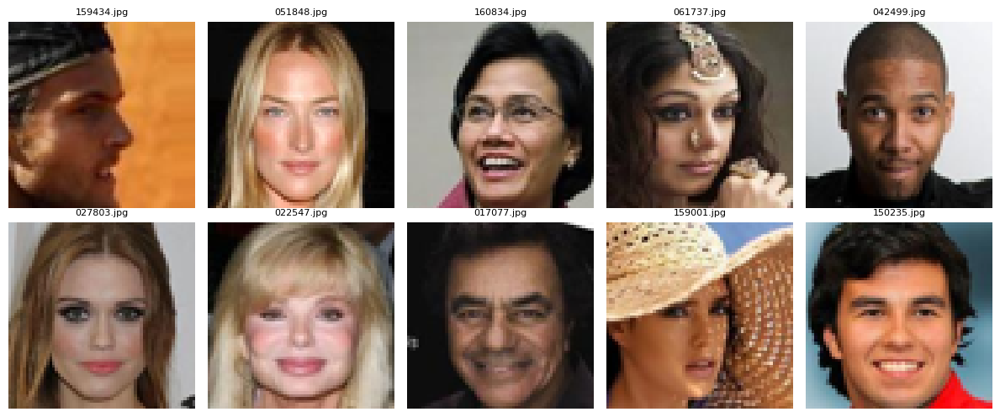

In [5]:
def show_images(images, titles=None, cols=5, figsize=(12, 8)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, index in zip(axes.flat, images, range(len(images))):
        ax.imshow(np.clip(image, 0, 1))
        ax.axis("off")
        if titles is not None:
            ax.set_title(str(titles[index]), fontsize=8)
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(len(x_train), size=10, replace=False)
show_images(x_train[sample_indices], ids_train[sample_indices], cols=5, figsize=(12, 5))


---

## **3. Encoder, decoder y autoencoder**

El **encoder** comprime cada cara RGB de `64x64x3` en un vector latente de `256` valores y el **decoder** devuelve tres canales RGB en `[0, 1]`. Mantenemos la resolución, los filtros de transición, el sobremuestreo bilineal del decoder y el latente de `AE_complex1_latent`.

La única modificación es un bloque residual tras cada convolución de transición:

```python
def res_block(x, filters):
    y = conv_block(x, filters)
    return layers.Add()([x, y])
```

### **Por qué esperamos una mejora**

Una conexión residual calcula $y = x + F(x)$: el bloque solo tiene que aprender una corrección sobre su entrada. A priori esto debería facilitar la optimización, mejorar el flujo del gradiente y añadir capacidad en cada resolución sin degradar el entrenamiento. También debería ayudar a conservar detalle fino (bordes, textura) que el FID penaliza.

### **Decisiones concretas**

- **Una sola convolución por rama residual**, seguida de `BatchNormalization` y `LeakyReLU`. Buscamos añadir capacidad con un coste moderado, en lugar de duplicar la profundidad con ramas de dos convoluciones.
- **`gamma_initializer="zeros"` en la `BatchNormalization` residual:** para estabilizar las primeras épocas.
- **Bloque residual después de la transición:** las convoluciones con `stride=2` cambian resolución y canales antes del `Add`, de modo que la rama principal y el atajo tienen formas compatibles.

No cambiamos la resolución ni el latente. Cualquier diferencia con `AE_complex1_latent` se atribuye al diseño residual, con la cautela de que el modelo tiene más parámetros por las convoluciones adicionales (lo cuantificamos en la sección 9).

In [ ]:
# Bloques convolucionales y residuales.
def conv_block(x, filters, kernel_size=3, strides=1, gamma_initializer="ones"):
    x = layers.Conv2D(
        filters,
        kernel_size=kernel_size,
        strides=strides,
        padding="same",
        use_bias=False,
    )(x)
    x = layers.BatchNormalization(gamma_initializer=gamma_initializer)(x)
    return layers.LeakyReLU(negative_slope=0.2)(x)


def res_block(x, filters):
    y = conv_block(x, filters, gamma_initializer="zeros")
    return layers.Add()([x, y])


# Las convoluciones de transición cambian resolución/canales; el ResBlock se aplica
# después, cuando la rama principal y el atajo tienen la misma forma.
encoder_inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="encoder_input")
x = conv_block(encoder_inputs, 32, kernel_size=4, strides=2)
x = res_block(x, 32)
for filters in (64, 128, 256):
    x = conv_block(x, filters, kernel_size=4, strides=2)
    x = res_block(x, filters)
    
x = layers.Flatten()(x)
z = layers.Dense(
    LATENT_DIM,
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_vector",
)(x)
encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")
encoder_ae.summary()

2026-11-01 11:22:01.020860: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-11-01 11:22:01.021036: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-11-01 11:22:01.021048: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
2026-11-01 11:22:01.021197: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-01 11:22:01.021216: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Model: "encoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │      1,536 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │      9,216 │ leaky_re_lu[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ leaky_re_lu[0][0… │
│                     │ 32)               │            │ leaky_re_lu_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │     32,768 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │     36,864 │ leaky_re_lu_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 16,    │          0 │ leaky_re_lu_2[0]… │
│                     │ 64)               │            │ leaky_re_lu_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 8, 8, 128) │    131,072 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 128) │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                 

 Total params: 2,525,696 (9.63 MB)

 Trainable params: 2,523,776 (9.63 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [7]:
decoder_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
x = layers.Dense(4 * 4 * 256, use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 256))(x)

for filters in (256, 128, 64, 32):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = conv_block(x, filters)
    x = res_block(x, filters)

decoder_outputs = layers.Conv2D(
    CHANNELS, kernel_size=3, padding="same", activation="sigmoid", name="decoder_output"
)(x)
decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")
decoder_ae.summary()


Model: "decoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ decoder_input       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4096)      │  1,048,576 │ decoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 4096)      │     16,384 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_8       │ (None, 4096)      │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 4, 4, 256) │          0 │ leaky_re_lu_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 8, 8, 256) │          0 │ reshape[0][0]     │
│ (UpSampling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8, 256) │    589,824 │ up_sampling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 256) │      1,024 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_9       │ (None, 8, 8, 256) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8, 256) │    589,824 │ leaky_re_lu_9[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 256) │      1,024 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_10      │ (None, 8, 8, 256) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 8, 8, 256) │          0 │ leaky_re_lu_9[0]… │
│                     │                   │            │ leaky_re_lu_10[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 16, 16,    │          0 │ add_4[0][0]       │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 16, 16,    │    294,912 │ up_sampling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_11      │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 16, 16,    │    147,456 │ leaky_re_lu_11[0… │
│                     │ 128)              │            │                 

 Total params: 2,829,923 (10.80 MB)

 Trainable params: 2,819,811 (10.76 MB)

 Non-trainable params: 10,112 (39.50 KB)

In [8]:
autoencoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="autoencoder_input")
autoencoder = keras.Model(
    autoencoder_input,
    decoder_ae(encoder_ae(autoencoder_input)),
    name="autoencoder",
)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_ae (Functional)         │ (None, 256)            │     2,525,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_ae (Functional)         │ (None, 64, 64, 3)      │     2,829,923 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,355,619 (20.43 MB)

 Trainable params: 5,343,587 (20.38 MB)

 Non-trainable params: 12,032 (47.00 KB)

---

## **4. Función de pérdida y optimización**

In [9]:
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    structural_loss = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return 0.5 * l1 + 0.5 * structural_loss

INITIAL_LEARNING_RATE = 1e-3
MIN_LEARNING_RATE = 1e-5
DECAY_STEPS = int(np.ceil(len(x_train) / BATCH_SIZE) * EPOCHS)
learning_rate_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=INITIAL_LEARNING_RATE,
    decay_steps=DECAY_STEPS,
    alpha=MIN_LEARNING_RATE / INITIAL_LEARNING_RATE,
)

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate_schedule),
    loss=ssim_l1_loss,
)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
]

---

## **5. Entrenamiento y guardado**

In [10]:
if TRAIN_MODEL:
    history_ae = autoencoder.fit(
        x_train,
        x_train,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        validation_data=(x_val, x_val),
        callbacks=callbacks,
    )
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    autoencoder.save(AE_PATH)
    encoder_ae.save(ENCODER_PATH)
    decoder_ae.save(DECODER_PATH)
    HISTORY_PATH.write_text(json.dumps({
        key: [float(value) for value in values]
        for key, values in history_ae.history.items()
    }, indent=2))
else:
    required = [AE_PATH, ENCODER_PATH, DECODER_PATH, HISTORY_PATH]
    missing = [str(path) for path in required if not path.exists()]
    if missing:
        raise FileNotFoundError("Faltan checkpoints para TRAIN_MODEL=False: " + ", ".join(missing))
    autoencoder = keras.models.load_model(AE_PATH, custom_objects={"ssim_l1_loss": ssim_l1_loss})
    encoder_ae = keras.models.load_model(ENCODER_PATH)
    decoder_ae = keras.models.load_model(DECODER_PATH)
    history_ae = type("History", (), {"history": json.loads(HISTORY_PATH.read_text())})()


Epoch 1/30


2026-11-01 11:22:48.454080: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


469/469 ━━━━━━━━━━━━━━━━━━━━ 207s 424ms/step - loss: 0.3107 - val_loss: 0.2075
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 221s 471ms/step - loss: 0.1919 - val_loss: 0.1932
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 224s 478ms/step - loss: 0.1633 - val_loss: 0.1711
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 226s 482ms/step - loss: 0.1484 - val_loss: 0.1569
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 214s 457ms/step - loss: 0.1389 - val_loss: 0.1469
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 220s 468ms/step - loss: 0.1323 - val_loss: 0.1429
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 228s 487ms/step - loss: 0.1270 - val_loss: 0.1399
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 221s 471ms/step - loss: 0.1228 - val_loss: 0.1399
Epoch 9/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 216s 461ms/step - loss: 0.1194 - val_loss: 0.1347
Epoch 10/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 214s 457ms/step - loss: 0.1166 - val_loss: 0.1307
Epoch 11/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 211s 450ms/step - loss: 0.1145 - val_loss: 0.1287
Epoch 12/30
469/469

In [11]:
val_losses = history_ae.history["val_loss"]
best_index = int(np.argmin(val_losses))

print(f"Mejor época: {best_index + 1}")
print(f"Loss de entrenamiento: {history_ae.history['loss'][best_index]:.6f}")
print(f"Val loss: {val_losses[best_index]:.6f}")

Mejor época: 30
Loss de entrenamiento: 0.094208
Val loss: 0.099840


---

## **6. Reconstrucciones en test**

Comprobamos que el autoencoder conserva la identidad visual de imágenes que no usó para actualizar sus pesos y representamos la evolución de la pérdida. La separación entre entrenamiento y validación (`0.0942` frente a `0.0998`) es pequeña, por lo que no vemos sobreajuste relevante. Después calculamos el FID de las reconstrucciones.

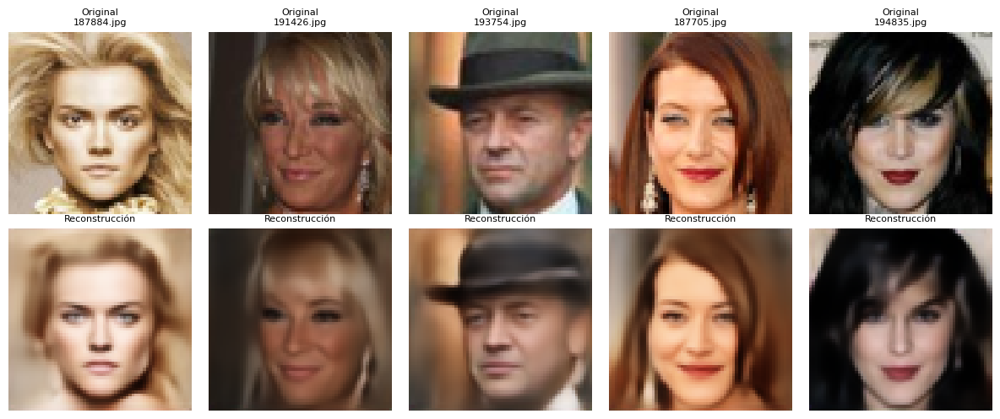

In [12]:
test_indices = sample_rng.choice(len(x_test), size=5, replace=False)
test_reconstructions = autoencoder.predict(x_test[test_indices], verbose=0)
comparison = np.concatenate([x_test[test_indices], test_reconstructions], axis=0)
titles = [f"Original\n{ids_test[i]}" for i in test_indices] + ["Reconstrucción"] * len(test_indices)
show_images(comparison, titles, cols=5, figsize=(12, 5))

Mejor época según val_loss: 30


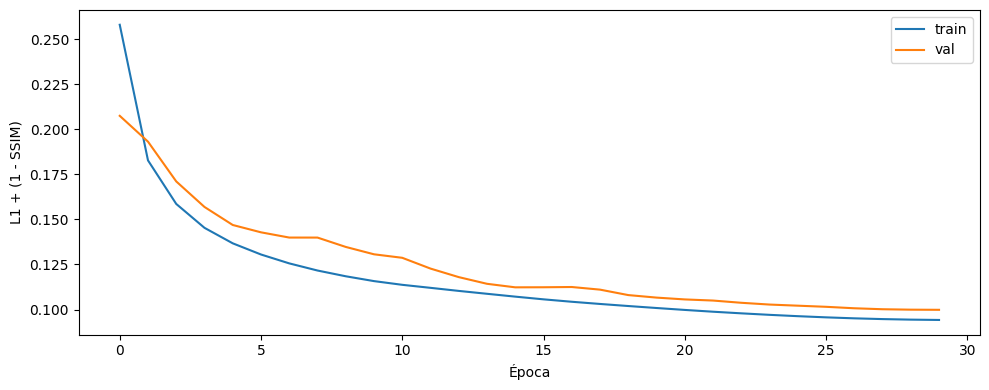

In [13]:
if hasattr(history_ae, "history") and "val_loss" in history_ae.history:
    best_epoch = int(np.argmin(history_ae.history["val_loss"])) + 1
    print(f"Mejor época según val_loss: {best_epoch}")
    plt.figure(figsize=(10, 4))
    plt.plot(history_ae.history["loss"], label="train")
    plt.plot(history_ae.history["val_loss"], label="val")
    plt.xlabel("Época")
    plt.ylabel("L1 + (1 - SSIM)")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [14]:
# FID de reconstrucciones y preparación para el FID del morphing
# El FID compara distribuciones de imágenes; por eso se usa un conjunto de test.
FID_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FID_REAL_SAMPLES = min(1000, len(x_test))
FID_BATCH_SIZE = 32


def prepare_images_for_fid(images):
    images = np.asarray(images)
    if images.ndim == 3:
        images = images[..., np.newaxis]
    if images.ndim != 4 or images.shape[-1] not in (1, 3):
        raise ValueError(f"Se esperaban imágenes con forma (N, H, W, 1|3); recibidas {images.shape}")
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
    if images.shape[-1] == 1:
        images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(np.ascontiguousarray(images))


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    generated_images = prepare_images_for_fid(generated_images)
    real_images = prepare_images_for_fid(real_images)
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(FID_DEVICE)
    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(FID_DEVICE), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(FID_DEVICE), real=False)
    return float(fid.compute().item())

In [15]:
fid_reconstruction_images = x_test[:FID_REAL_SAMPLES]
fid_reconstruction_reference = x_test[FID_REAL_SAMPLES:2 * FID_REAL_SAMPLES]
reconstructed_test_images = autoencoder.predict(
    fid_reconstruction_images,
    batch_size=FID_BATCH_SIZE,
    verbose=0,
)
reconstruction_fid = calculate_fid(
    reconstructed_test_images,
    fid_reconstruction_reference,
)
print(f"FID de reconstrucciones ({FID_REAL_SAMPLES} imágenes): {reconstruction_fid:.4f}")

FID de reconstrucciones (1000 imágenes): 64.4005


---

## **7. FID y morphing mediante interpolación en el espacio latente**

Usamos el mismo protocolo de FID que en `AE_complex1` y `AE_complex1_latent`: 1000 reconstrucciones de `test` frente a 1000 imágenes reales distintas de `test`. Un FID más bajo indica que las imágenes se parecen más, en distribución, a las reales; no mide la identidad de una imagen concreta.

Obtenemos un FID de reconstrucción de `64.40`, frente a `63.65` de `AE_complex1_latent` y `72.94` de `AE_complex1`. **El FID ha empeorado ligeramente** al añadir bloques residuales, a pesar de que la pérdida de validación sí ha bajado. Lo interpretamos en la sección 9.

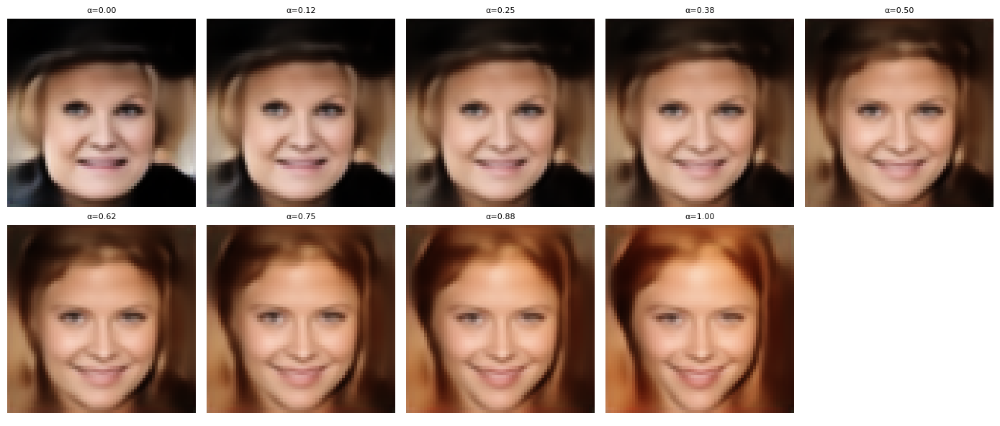

A: 182638.jpg | B: 182640.jpg


In [16]:
def morph_images(image_a, image_b, steps=9):
    if image_a.shape != image_b.shape:
        raise ValueError(f"Las imágenes deben tener la misma forma; recibidas {image_a.shape} y {image_b.shape}")
    z_a = encoder_ae.predict(image_a[None, ...], verbose=0)[0]
    z_b = encoder_ae.predict(image_b[None, ...], verbose=0)[0]
    alphas = np.linspace(0.0, 1.0, steps, dtype=np.float32)
    latent_path = (1.0 - alphas[:, None]) * z_a + alphas[:, None] * z_b
    return alphas, decoder_ae.predict(latent_path, verbose=0)

morph_a_index, morph_b_index = 0, 1
alphas, morph_sequence = morph_images(x_test[morph_a_index], x_test[morph_b_index], steps=9)
show_images(
    morph_sequence,
    [f"α={alpha:.2f}" for alpha in alphas],
    cols=5,
    figsize=(14, 6),
)
print(f"A: {ids_test[morph_a_index]} | B: {ids_test[morph_b_index]}")

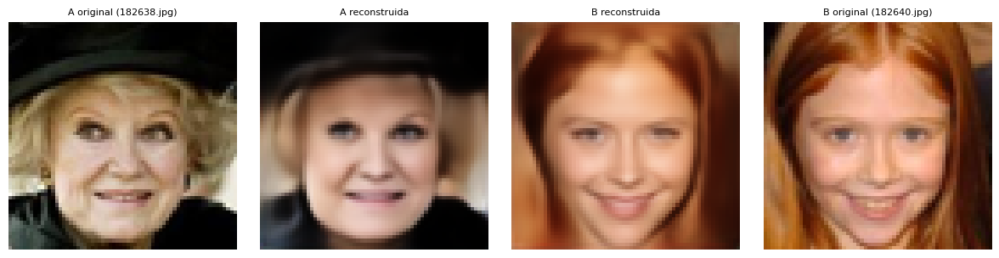

In [17]:
# Comparación de extremos: original frente a reconstrucción usada en la interpolación.
endpoints = np.stack([
    x_test[morph_a_index], morph_sequence[0],
    morph_sequence[-1], x_test[morph_b_index],
])
show_images(
    endpoints,
    [f"A original ({ids_test[morph_a_index]})", "A reconstruida", "B reconstruida", f"B original ({ids_test[morph_b_index]})"],
    cols=4,
    figsize=(12, 3),
)

---

## **8. Secuencia visual y GIF del morphing**


In [18]:
GIF_PATH = PROCESSED_DIR.parent.parent / "gif" / "fusion_ae2_residual256_morphing.gif"
N_FRAMES = 80
FRAME_MS = 50

z_a = encoder_ae.predict(
    x_test[morph_a_index][None, ...],
    verbose=0,
)[0]
z_b = encoder_ae.predict(
    x_test[morph_b_index][None, ...],
    verbose=0,
)[0]

alphas = np.linspace(0.0, 1.0, N_FRAMES, dtype=np.float32)
z_frames = (1.0 - alphas[:, None]) * z_a + alphas[:, None] * z_b

decoded = decoder_ae.predict(z_frames, verbose=0)

GIF guardado en '/Users/dani22/Desktop/ProyectoCD/morphing/gif/fusion_ae2_residual256_morphing.gif' | 80 fotogramas


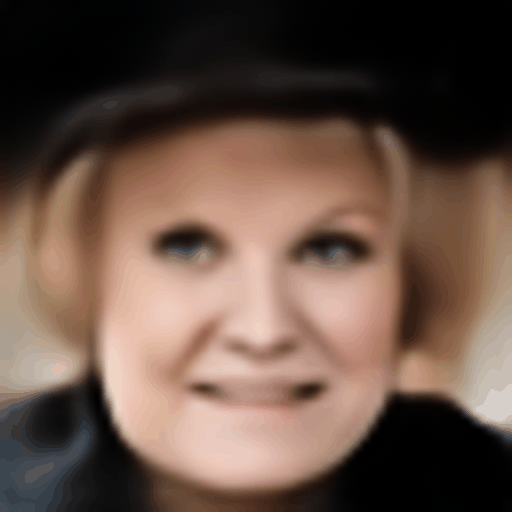

In [19]:
frames = [
    Image.fromarray((np.clip(image, 0, 1) * 255).astype(np.uint8))
    .resize((512, 512), Image.Resampling.BICUBIC)
    for image in decoded
]

gif_path = Path(GIF_PATH).resolve()
gif_path.parent.mkdir(parents=True, exist_ok=True)
if not frames:
    raise RuntimeError("No se generaron fotogramas para el GIF")

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=FRAME_MS,
    loop=0,
)

print(f"GIF guardado en '{gif_path}' | {len(frames)} fotogramas")
display(IPyImage(filename=str(gif_path)))

---

## **9. Decisiones de diseño, conclusiones y siguiente paso**

### **9.1 Resultados**

| Modelo | Latente | FID reconstrucción | `val_loss` |
| --- | --- | --- | --- |
| `AE_complex1` | 128 | 72.94 | 0.1351 |
| `AE_complex1_latent` | 256 | **63.65** | 0.1077 |
| `AE_complex2` (residual) | 256 | 64.40 | **0.0998** |

El bloque residual reduce la pérdida de validación un `7 %`, pero el FID empeora en `0.75` puntos (alrededor de un `1 %`). Con solo 1000 imágenes, una diferencia de menos de un punto de FID está en el orden del ruido de la métrica, así que no podemos afirmar que sea una degradación real. Lo que sí podemos afirmar es que **no hay una mejora perceptible**.

### **9.2 Por qué la arquitectura residual no nos beneficia**

Esperábamos a priori una mejora, pero tiene sentido que no aparezca:

- **La red no es profunda.** Solo tenemos cuatro etapas de reducción y cuatro de ampliación. Las conexiones residuales resuelven sobre todo el problema de optimización de redes muy profundas, y aquí no hay un problema de vanishing gradient porque el `BatchNormalization` mantiene los gradientes bien propagados.
- **El cuello de botella sigue siendo el latente.** Las conexiones residuales están *dentro* del encoder y del decoder; no atraviesan el vector de `256` dimensiones. Toda la información de la imagen tiene que pasar igualmente por él, así que un atajo interno no puede devolver el detalle que el latente no almacena. Eso es lo contrario a las conexiones de salto tipo U-Net, que además romperían el morphing por no pasar solo por el latente.
- **La pérdida y el FID miden cosas distintas.** $L_1$ + SSIM mejora con más capacidad, pero el FID mide realismo perceptual en el espacio de Inception. Más capacidad reduce el error medio, pero no necesariamente hace las imágenes más nítidas o realistas.

Con independencia de que el resultado sea algo peor, como en este caso, o hubiera sido mínimamente mejor, la conclusión sería la misma: **las mejoras son marginales y no justifican el coste**.

### **9.3 Coste computacional y parámetros**

Los bloques residuales añaden alrededor de un `40 %` más de parámetros y un `60 %` más de cómputo, porque las convoluciones `3x3` adicionales se aplican a resoluciones altas en el decoder. En resumen: pagamos un coste claramente superior a cambio de una mejora de FID nula.

### **9.4 Una decisión común a toda la serie: RGB frente a escala de grises**

Todos los notebooks tratan las caras como imágenes RGB de `3` canales. ¿Qué pasaría con `1` canal?

- **Parámetros:** casi nada cambia. Solo dos capas dependen del número de canales: la primera convolución del encoder (de `4·4·3·32 = 1536` a `512` pesos) y la última del decoder. En total ahorraríamos unos `2 000` parámetros de más de `3.7 M`, menos de un `0.1 %`. La inmensa mayoría de los parámetros está en las capas internas.

- **Velocidad:** tampoco cambiaría de forma apreciable. El cómputo está dominado por las capas internas. Las ganancias reales serían tres veces menos memoria para guardar el conjunto de datos y menos transferencia de datos, pero no un entrenamiento notablemente más rápido.

- **Latente:** la dimensión latente es una decisión independiente del número de canales; con `256` valores el tamaño del modelo sería el mismo. Lo que cambia es la **relación de compresión**: pasaríamos de `12288 / 256 = 48` a `4096 / 256 = 16` valores de entrada por coordenada. Con el mismo latente, el cuello de botella sería mucho menos estricto, porque solo hay que codificar la luminancia. Por ello esperaríamos reconstrucciones mejores en escala de grises, y podríamos reducir el latente manteniendo la calidad.

- **¿Entrenar en gris y pasar a RGB para el GIF?** No es una conversión directa. Pasar de gris a RGB repitiendo el canal produce otra imagen gris, no recupera el color. Habría que tratar el color por separado: por ejemplo, entrenar el autoencoder sobre la luminancia (Y de YCbCr) e interpolar Cb y Cr entre las dos caras. Esa interpolación sería lineal en el espacio de píxeles (el tipo de mezcla que queremos evitar), aunque la crominancia es de baja frecuencia y el *ghosting* sería poco visible. Otra opción es una red de colorización posterior, que añade otro modelo a entrenar. Además, el FID se calcula con una red Inception entrenada con color, por lo que no sería comparable con los valores de esta serie salvo que comparásemos gris con gris.

Por tanto, la escala de grises **no nos aportaría un ahorro computacional relevante** porque el coste no está en los canales de entrada, y que sí simplificaría la tarea del autoencoder a costa de renunciar al color o de complicar el pipeline. No lo hemos probado en este notebook, por lo que son expectativas basadas en el análisis de la arquitectura y no resultados medidos. Mantenemos RGB porque el objetivo final es un morphing facial en color.

### **9.5 Siguiente paso**

Hemos visto que ni ampliar la profundidad con bloques residuales (a priori con este tipo de arquitectura pequeña) ni (previsiblemente) quitar el color resolverían el problema principal. Las reconstrucciones siguen siendo emborronadas porque la pérdida $L_1$ + SSIM no captura bien la nitidez perceptual. El siguiente paso es cambiar el **objetivo** y no la arquitectura: una **pérdida basada en una red preentrenada (VGG)**, que compara las imágenes en el espacio de características y debería penalizar mejor la pérdida de detalle. Lo desarrollamos en `AE_complex2_VGG.ipynb`.